# SMS Spam Detection (TF-IDF + SVM)
Project 9: sort SMS messages into **spam** or **ham** (ham just means a normal message).

- Dataset: SMS Spam Collection (UCI)
- Model: TF-IDF + Linear SVM
- Metrics: Accuracy, Precision, Recall, F1
- Demo: Streamlit

Run the cells from top to bottom with Shift + Enter.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

## 2. Load the data
The dataset is a zip file on the UCI site. Inside is one tab separated file, each line is `label<TAB>message`.
If the direct download fails, the second option uses the `ucimlrepo` package.

In [2]:
def load_sms():
    # option 1: download the zip straight from UCI
    try:
        import urllib.request, zipfile, io
        url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
        raw = urllib.request.urlopen(url).read()          # download the bytes
        with zipfile.ZipFile(io.BytesIO(raw)) as z:       # open the zip from memory
            with z.open("SMSSpamCollection") as f:
                return pd.read_csv(f, sep="\t", names=["label", "text"])
    except Exception as e:
        print("direct download failed:", e)

    # option 2: ucimlrepo
    get_ipython().system("pip install -q ucimlrepo")
    from ucimlrepo import fetch_ucirepo
    sms = fetch_ucirepo(id=228)
    return pd.DataFrame({"label": sms.data.targets.iloc[:, 0],
                         "text": sms.data.features.iloc[:, 0]})

df = load_sms()
print(df.shape)
df.head()

(5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 3. Look at the data and clean it
Two things to check:
1. How many spam vs ham. If spam is rare, accuracy alone can fool us.
2. Duplicate messages. If the same message ends up in both train and test, the score looks better than it really is.

In [3]:
print(df["label"].value_counts())
print()
print("duplicates:", df.duplicated().sum())

df = df.dropna().drop_duplicates().reset_index(drop=True)   # remove empty rows and duplicates
print("after cleaning:", df.shape)

df["y"] = (df["label"] == "spam").astype(int)   # spam = 1, ham = 0

# peek at a few messages from each class
for lab in ["ham", "spam"]:
    print("\n---", lab, "---")
    for t in df[df["label"] == lab]["text"].head(3):
        print("*", t[:120])

label
ham     4825
spam     747
Name: count, dtype: int64

duplicates: 403
after cleaning: (5169, 2)

--- ham ---
* Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
* Ok lar... Joking wif u oni...
* U dun say so early hor... U c already then say...

--- spam ---
* Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt r
* FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std
* WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. C


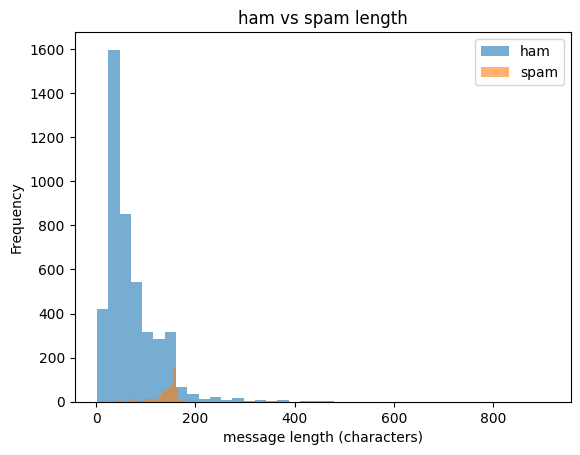

In [4]:
# are spam messages longer?
df["length"] = df["text"].str.len()
df.groupby("label")["length"].plot(kind="hist", bins=40, alpha=0.6, legend=True)
plt.xlabel("message length (characters)")
plt.title("ham vs spam length")
plt.show()

## 4. Train / test split
80% for training, 20% for testing. `stratify=y` keeps the spam percentage the same in both parts.

In [5]:
X = df["text"]
y = df["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("train:", len(X_train), "test:", len(X_test))
print("spam share  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

train: 4135 test: 1034
spam share  train: 0.126  test: 0.127


## 5. TF-IDF + SVM
A model can't read text, so TF-IDF turns every message into numbers (one column per word).
A word gets a high score if it shows up a lot in that message but not in most other messages. So "the" scores low and "winner" scores high.

The pipeline chains TF-IDF and the SVM together. It learns the vocabulary from the training data only, so nothing leaks from the test set.

In [6]:
svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, stop_words="english")),  # text -> numbers
    ("clf", LinearSVC(random_state=42)),                               # linear SVM
])

svm_model.fit(X_train, y_train)     # learn vocabulary + train the SVM
y_pred = svm_model.predict(X_test)  # predict on messages it has never seen

print("vocabulary size:", len(svm_model.named_steps["tfidf"].vocabulary_))

vocabulary size: 7414


## 6. Evaluate
Only about 13% of the messages are spam, so a model that says "ham" every time would already get ~87% accuracy. That's why we also check:
- **Precision**: of the messages we called spam, how many really were spam
- **Recall**: of all the real spam, how many we caught
- **F1**: one number that balances precision and recall

Accuracy : 0.9778
Precision: 0.9655
Recall   : 0.855
F1       : 0.9069

              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       903
        spam       0.97      0.85      0.91       131

    accuracy                           0.98      1034
   macro avg       0.97      0.93      0.95      1034
weighted avg       0.98      0.98      0.98      1034



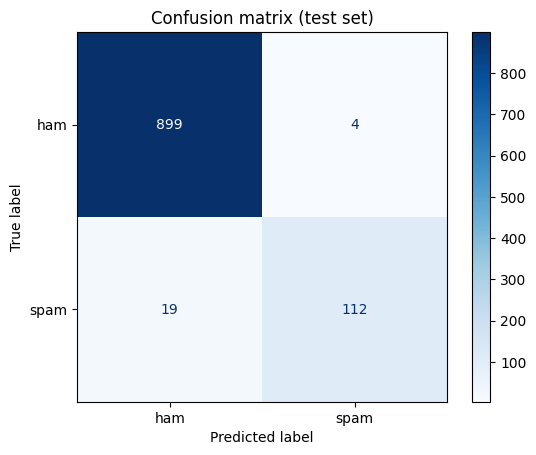

In [7]:
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1       :", round(f1_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=["ham", "spam"]))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["ham", "spam"]).plot(cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.show()

How to read the matrix: top right = normal messages wrongly marked as spam, bottom left = spam that got through.
Think about which mistake is worse for a phone user, it's a good point for the report.

## 7. Cross-validation
One split can be lucky or unlucky. 5-fold cross-validation trains and tests 5 times on different splits and gives the average.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_validate(svm_model, X, y, cv=cv,
                        scoring=["accuracy", "precision", "recall", "f1"])

for m in ["accuracy", "precision", "recall", "f1"]:
    s = scores["test_" + m]
    print(f"{m:10s} {s.mean():.4f} (+/- {s.std():.4f})")

accuracy   0.9837 (+/- 0.0033)
precision  0.9768 (+/- 0.0116)
recall     0.8928 (+/- 0.0298)
f1         0.9326 (+/- 0.0144)


## 8. Compare with other models
Same TF-IDF features, three different classifiers.

In [9]:
models = {
    "Linear SVM": LinearSVC(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
}

rows = []
for name, clf in models.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(stop_words="english")), ("clf", clf)])
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, p),
                 "Precision": precision_score(y_test, p),
                 "Recall": recall_score(y_test, p),
                 "F1": f1_score(y_test, p)})

results = pd.DataFrame(rows).round(4).set_index("Model")
results

,Accuracy,Precision,Recall,F1
Model,,,,
Linear SVM,0.9778,0.9655,0.8550,0.9069
Logistic Regression,0.9565,0.9778,0.6718,0.7964
Naive Bayes,0.9671,1.0000,0.7405,0.8509


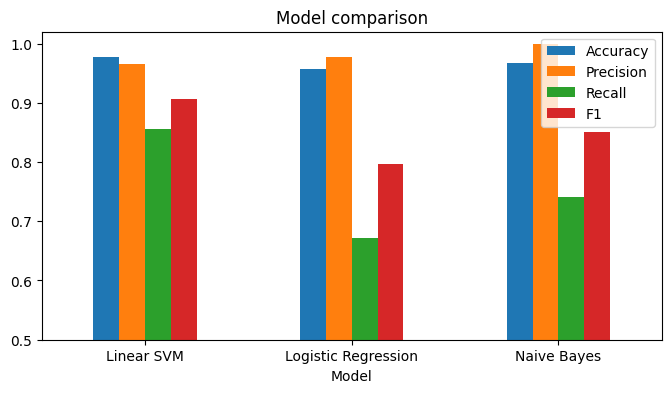

In [10]:
results.plot(kind="bar", figsize=(8, 4))
plt.ylim(0.5, 1.02)
plt.xticks(rotation=0)
plt.title("Model comparison")
plt.show()

## 9. Which words matter?
A linear model gives each word a weight. Big positive weight = pushes towards spam, big negative = pushes towards ham.

In [11]:
tfidf = svm_model.named_steps["tfidf"]
clf = svm_model.named_steps["clf"]

words = np.array(tfidf.get_feature_names_out())
order = np.argsort(clf.coef_[0])     # smallest weight first

print("spam words:", list(words[order[-15:]][::-1]))
print()
print("ham words :", list(words[order[:15]]))

spam words: ['uk', 'txt', 'www', 'claim', 'mobile', '50', 'service', '150p', 'reply', 'http', 'urgent', 'ringtone', '07090201529', 'com', 'prize']

ham words : ['liked', 'home', 'fullonsms', 'way', 'll', 'mail', 'later', 'did', 'lt', 'cool', 'yup', 'said', 'gt', 'hey', 'ok']


## 10. Where does it go wrong?

In [12]:
wrong = (y_pred != y_test.values)
errors = pd.DataFrame({"text": X_test[wrong],
                       "true": y_test[wrong].map({0: "ham", 1: "spam"})})

print("mistakes:", len(errors), "out of", len(y_test))
pd.set_option("display.max_colwidth", 120)
errors.head(10)

mistakes: 23 out of 1034


,text,true
1459,Thanks for the Vote. Now sing along with the stars with Karaoke on your mobile. For a FREE link just reply with SING...,spam
5137,Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min Gsex POBOX 2667 WC1N 3XX,spam
521,You will recieve your tone within the next 24hrs. For Terms and conditions please see Channel U Teletext Pg 750,spam
1611,Hi if ur lookin 4 saucy daytime fun wiv busty married woman Am free all next week Chat now 2 sort time 09099726429 J...,spam
5139,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT....,spam
1423,Hi its LUCY Hubby at meetins all day Fri & I will B alone at hotel U fancy cumin over? Pls leave msg 2day 0909972639...,spam
3949,Missed call alert. These numbers called but left no message. 07008009200,spam
4806,K k:) sms chat with me.,ham
661,"SMS. ac sun0819 posts HELLO:""You seem cool, wanted to say hi. HI!!!"" Stop? Send STOP to 62468",spam
2303,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about ...,spam


## 11. Try your own messages

In [13]:
my_messages = [
    "Congratulations! You have won a free prize. Call now to claim your reward",
    "Hey, are we still meeting for lunch tomorrow?",
    "URGENT: your account is suspended. Click the link to verify",
]

for msg, p in zip(my_messages, svm_model.predict(my_messages)):
    print("SPAM" if p == 1 else "ham ", "|", msg)

SPAM | Congratulations! You have won a free prize. Call now to claim your reward
ham  | Hey, are we still meeting for lunch tomorrow?
SPAM | URGENT: your account is suspended. Click the link to verify


## 12. Save the model
The whole pipeline (TF-IDF + SVM) goes into one file, so the app can load it without training again.

In [14]:
import joblib
joblib.dump(svm_model, "spam_model.joblib")
print("saved spam_model.joblib")

saved spam_model.joblib


## 13. Streamlit app
The sheet asks for Streamlit. First cell writes the app into a file called `app.py`, then we run it.

In [15]:
%%writefile app.py
import streamlit as st
import joblib

model = joblib.load("spam_model.joblib")

st.title("SMS Spam Detector")
st.write("TF-IDF + SVM trained on the UCI SMS Spam Collection")

msg = st.text_area("Type or paste an SMS message")

if st.button("Check"):
    if msg.strip() == "":
        st.warning("Type a message first")
    else:
        pred = model.predict([msg])[0]
        score = model.decision_function([msg])[0]   # distance from the SVM boundary
        if pred == 1:
            st.error("SPAM")
        else:
            st.success("Not spam (ham)")
        st.caption("SVM score: " + str(round(float(score), 2)) + " (above 0 means spam)")

Writing app.py


Colab can't open a Streamlit page directly, so we use a Cloudflare tunnel to get a public link.
1. Run the install cell (Streamlit + cloudflared)
2. Run the last cell and wait about 10 seconds. It prints a link ending in `trycloudflare.com`
3. Open that link. No password needed.

(localtunnel also works sometimes, but it often fails to load Streamlit's JavaScript files, so I'm using Cloudflare.)

In [16]:
!pip install -q streamlit
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

In [17]:
import subprocess, time, re

# start streamlit in the background
subprocess.Popen(["streamlit", "run", "app.py",
                  "--server.port", "8501",
                  "--server.headless", "true",
                  "--server.enableCORS", "false",
                  "--server.enableXsrfProtection", "false"],
                 stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(5)

# start the tunnel and read the public link from its log
tunnel = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)

for line in tunnel.stdout:
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", line)
    if m:
        print("Open this link:", m.group(0))
        break

Open this link: https://constitutional-marion-hourly-firms.trycloudflare.com


## 14. Report checklist
- **Problem:** classify SMS as spam or ham
- **Dataset:** UCI SMS Spam Collection, 5,574 messages (mention how many are left after removing duplicates, and the spam %)
- **Method:** TF-IDF + Linear SVM in a Pipeline, 80/20 stratified split, 5-fold cross-validation
- **Results:** accuracy, precision, recall, F1, confusion matrix, model comparison table
- **Analysis:** why accuracy alone is misleading, top spam words, examples of mistakes
- **Things to try next:** `class_weight="balanced"` on the SVM, `ngram_range=(1, 2)` in TfidfVectorizer, tune `C` with GridSearchCV, or compare with DistilBERT (the sheet lists it as an option)